# Task 4: Relativistic Redshift Prediction & Recession Velocity Estimation
**Author:** Somil (`dev-somil`)  
**Dataset:** `../data/processed/sdss_clean.csv` (Sloan Digital Sky Survey — SDSS17)

## Objective
1. Treat the 5 photometric light bands ($u, g, r, i, z$) as input feature vectors in $\mathbb{R}^5$ and train a **Linear Regression** model to predict each celestial object's redshift ($z$).
2. Pass the predicted redshifts into the **Relativistic Doppler formula** (derived symbolically in Task 1) to estimate each object's recession velocity as a fraction of the speed of light ($\beta = v/c$).
3. Evaluate prediction accuracy using $R^2$, RMSE, and MAE, and export 300 DPI diagnostic plots to `../figures/`.

## 1. Environment Setup & Data Loading
We load the cleaned SDSS17 dataset generated in Task 1 using a relative path (`../data/processed/sdss_clean.csv`) to maintain cross-machine reproducibility. We also lock in the team's standardized class color palette (`STAR` = gold, `GALAXY` = royalblue, `QSO` = crimson) for visual consistency across all project figures.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

#Load's the cleaned data set 
df = pd.read_csv('../data/processed/sdss_clean.csv')

print(f"Dataset shape: {df.shape}")
print(df.head())

#TEAM'S STANDARD COLOR PALETTE 
CLASS_COLORS = {
    'STAR' : 'gold',
    'GALAXY' : 'royalblue',
    'QSO' : 'crimson'
}

Dataset shape: (99999, 7)
          u         g         r         i         z  redshift   class
0  23.87882  22.27530  20.39501  19.16573  18.79371  0.634794  GALAXY
1  24.77759  22.83188  22.58444  21.16812  21.61427  0.779136  GALAXY
2  25.26307  22.66389  20.60976  19.34857  18.94827  0.644195  GALAXY
3  22.13682  23.77656  21.61162  20.50454  19.25010  0.932346  GALAXY
4  19.43718  17.58028  16.49747  15.97711  15.54461  0.116123  GALAXY


## 2. Linear Regression on 5D Spectral Vectors
We model the relationship between an object's 5 photometric light bands and its observed redshift ($z$) as a linear hyperplane in $\mathbb{R}^5$:

$$\hat{z} = w_u u + w_g g + w_r r + w_i i + w_z z_{\text{band}} + b$$

* **Train/Test Split:** 80% training, 20% testing, with `random_state=42` locked so all metrics and plots remain reproducible across runs.
* **Evaluation Metrics:** We measure model fit using the Coefficient of Determination ($R^2$), Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE).

In [3]:
# Features (5D spectral vectors) and target (redshift)
features = ['u', 'g', 'r', 'i', 'z']
X = df[features]
y = df['redshift']
classes = df['class']

# 80/20 Train-Test split (keep class labels aligned for plotting)
X_train, X_test, y_train, y_test, class_train, class_test = train_test_split(
    X, y, classes, test_size=0.2, random_state=42
)

# Fit Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# Predict redshift on the test set
z_pred = model.predict(X_test)

# Evaluation metrics
r2 = r2_score(y_test, z_pred)
rmse = np.sqrt(mean_squared_error(y_test, z_pred))
mae = mean_absolute_error(y_test, z_pred)

print(f"R² Score: {r2:.4f}")
print(f"RMSE:     {rmse:.4f}")
print(f"MAE:      {mae:.4f}")
print("\nLearned Coefficients:")
for band, coef in zip(features, model.coef_):
    print(f"  {band}: {coef:.4f}")
print(f"  Intercept: {model.intercept_:.4f}")

R² Score: 0.2789
RMSE:     0.6210
MAE:      0.3656

Learned Coefficients:
  u: -0.0306
  g: -0.0742
  r: -0.0149
  i: 0.2766
  z: 0.0417
  Intercept: -2.9833


## 3. Relativistic Recession Velocity ($\beta = v/c$)
From Special Relativity (Task 1 SymPy derivation), the observed redshift $z$ is related to an object's recession velocity $\beta = v/c$ by Einstein's Relativistic Doppler equation:

$$1 + z = \sqrt{\frac{1 + \beta}{1 - \beta}} \implies \beta(z) = \frac{(z + 1)^2 - 1}{(z + 1)^2 + 1}$$

Because $\lim_{z \to \infty} \beta(z) = 1$, this non-linear transformation guarantees that even at extreme redshifts, predicted velocities asymptotically approach—and never exceed—the speed of light ($c$).

In [5]:
def redshift_to_beta(z):
    """Converts redshift (z) to relativistic velocity fraction (beta = v/c)."""
    z_plus_1_sq = (z + 1.0) ** 2
    return (z_plus_1_sq - 1.0) / (z_plus_1_sq + 1.0)

# Clip extreme negative predictions if any occur so (z + 1) stays physically valid
z_pred_clipped = np.clip(z_pred, -0.99, None)

beta_actual = redshift_to_beta(y_test.values)
beta_pred = redshift_to_beta(z_pred_clipped)

beta_r2 = r2_score(beta_actual, beta_pred)
beta_rmse = np.sqrt(mean_squared_error(beta_actual, beta_pred))

print(f"Velocity (beta) R² Score: {beta_r2:.4f}")
print(f"Velocity (beta) RMSE:     {beta_rmse:.4f} c")
print(f"Max Actual Velocity:      {beta_actual.max():.4f} c")
print(f"Max Predicted Velocity:   {beta_pred.max():.4f} c")

Velocity (beta) R² Score: 0.2016
Velocity (beta) RMSE:     0.2384 c
Max Actual Velocity:      0.9693 c
Max Predicted Velocity:   0.9161 c


## 4. Visualization 1: Predicted vs. Actual Redshift ($z$)
We plot the true redshift ($z$) against the Linear Regression predictions ($\hat{z}$), color-coded by celestial class. Points lying close to the dashed ideal fit line ($y = x$) indicate accurate predictions, while deviations highlight where a purely linear model struggles with non-linear spectral behavior (such as high-redshift Quasars).

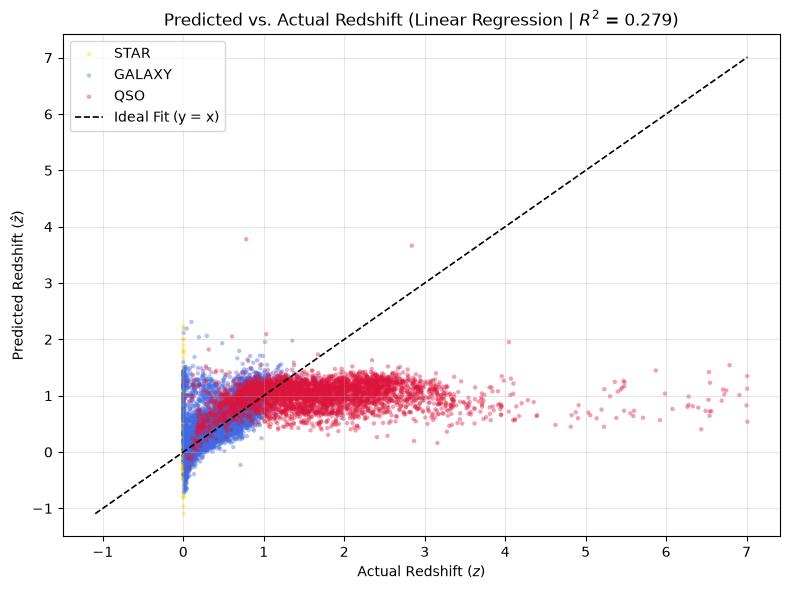

In [6]:
plt.figure(figsize=(8, 6))

for obj_class, color in CLASS_COLORS.items():
    mask = (class_test.values == obj_class)
    plt.scatter(
        y_test.values[mask], z_pred[mask],
        c=color, label=obj_class, alpha=0.4, s=10, edgecolors='none'
    )

# Ideal y = x reference line
lims = [min(y_test.min(), z_pred.min()), max(y_test.max(), z_pred.max())]
plt.plot(lims, lims, 'k--', linewidth=1.2, label='Ideal Fit (y = x)')

plt.title(f'Predicted vs. Actual Redshift (Linear Regression | $R^2$ = {r2:.3f})')
plt.xlabel('Actual Redshift ($z$)')
plt.ylabel('Predicted Redshift ($\\hat{z}$)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/04_redshift_predicted_vs_actual.png', dpi=300)
plt.show()

## 5. Visualization 2: Predicted vs. Actual Relativistic Velocity ($\beta = v/c$)
Mapping both actual and predicted redshifts through $\beta(z)$ lets us visualize how fast Stars, Galaxies, and Quasars are receding from Earth as a fraction of the speed of light, bounded physically by the dashed asymptote at $c = 1.0$.

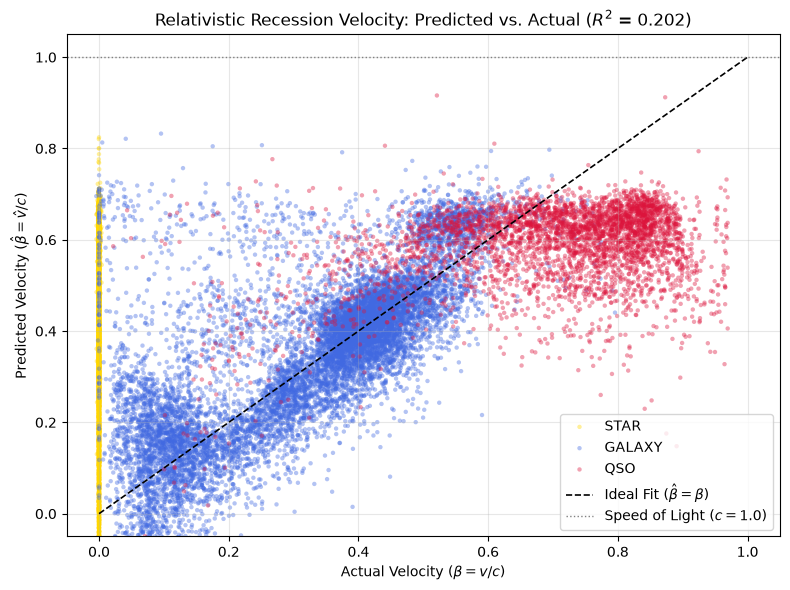

In [7]:
plt.figure(figsize=(8, 6))

for obj_class, color in CLASS_COLORS.items():
    mask = (class_test.values == obj_class)
    plt.scatter(
        beta_actual[mask], beta_pred[mask],
        c=color, label=obj_class, alpha=0.4, s=10, edgecolors='none'
    )

plt.plot([0, 1], [0, 1], 'k--', linewidth=1.2, label='Ideal Fit ($\\hat{\\beta} = \\beta$)')
plt.axhline(1.0, color='gray', linestyle=':', linewidth=1, label='Speed of Light ($c = 1.0$)')

plt.title(f'Relativistic Recession Velocity: Predicted vs. Actual ($R^2$ = {beta_r2:.3f})')
plt.xlabel('Actual Velocity ($\\beta = v/c$)')
plt.ylabel('Predicted Velocity ($\\hat{\\beta} = \\hat{v}/c$)')
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/04_velocity_predicted_vs_actual.png', dpi=300)
plt.show()

## 6. Upgrade 1: Astrophysics Feature Engineering (Color Indices)
Raw magnitudes (`u, g, r, i, z`) measure apparent brightness, which confuses dim nearby stars with bright distant galaxies. Astronomers isolate spectral shape using **color indices** (differences between adjacent bands):

$$c_1 = u - g, \quad c_2 = g - r, \quad c_3 = r - i, \quad c_4 = i - z$$

Because linear combinations of `u, g, r, i, z` are linearly dependent on the original features, we include both the **color indices** and their **squared terms** ($c_1^2, c_2^2, c_3^2, c_4^2$) alongside the reference brightness band (`r`) and key color interactions. This lets our regression surface curve to follow non-linear Quasar redshifts while remaining linear in its learnable weights.

In [8]:
from sklearn.preprocessing import StandardScaler

# 1. Engineer astrophysical color indices
df_eng = pd.DataFrame(index=df.index)
df_eng['r_mag'] = df['r']  # Reference brightness band
df_eng['u_g'] = df['u'] - df['g']
df_eng['g_r'] = df['g'] - df['r']
df_eng['r_i'] = df['r'] - df['i']
df_eng['i_z'] = df['i'] - df['z']

# 2. Add non-linear (quadratic & interaction) color terms
for col in ['u_g', 'g_r', 'r_i', 'i_z']:
    df_eng[f'{col}_sq'] = df_eng[col] ** 2

df_eng['ug_x_gr'] = df_eng['u_g'] * df_eng['g_r']
df_eng['gr_x_ri'] = df_eng['g_r'] * df_eng['r_i']
df_eng['ri_x_iz'] = df_eng['r_i'] * df_eng['i_z']

# 3. Same 80/20 split (locked random_state=42 for fair comparison)
X_eng_train, X_eng_test, y_eng_train, y_eng_test, class_eng_train, class_eng_test = train_test_split(
    df_eng, y, classes, test_size=0.2, random_state=42
)

# 4. Standardize features (critical so Gradient Descent converges smoothly)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_eng_train)
X_test_scaled = scaler.transform(X_eng_test)

print(f"Engineered feature matrix shape: {X_train_scaled.shape}")
print("Features:", list(df_eng.columns))

Engineered feature matrix shape: (79999, 12)
Features: ['r_mag', 'u_g', 'g_r', 'r_i', 'i_z', 'u_g_sq', 'g_r_sq', 'r_i_sq', 'i_z_sq', 'ug_x_gr', 'gr_x_ri', 'ri_x_iz']


## 7. Upgrade 2: Gradient Descent From Scratch (Multivariate Calculus)
Instead of treating `scikit-learn` as a black box, we minimize the **Mean Squared Error (MSE)** cost function directly using **Gradient Descent**:

$$J(\mathbf{w}, b) = \frac{1}{n} \sum_{i=1}^{n} (\hat{z}_i - z_i)^2, \quad \text{where } \hat{\mathbf{z}} = \mathbf{X}\mathbf{w} + b$$

Taking the partial derivatives with respect to the weight vector $\mathbf{w}$ and bias $b$ gives the exact gradient vector:

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{2}{n}\mathbf{X}^T(\mathbf{X}\mathbf{w} + b - \mathbf{z}), \qquad \frac{\partial J}{\partial b} = \frac{2}{n}\sum_{i=1}^{n}(\hat{z}_i - z_i)$$

At each iteration, we step opposite the gradient with learning rate $\alpha$:

$$\mathbf{w} \leftarrow \mathbf{w} - \alpha \frac{\partial J}{\partial \mathbf{w}}, \qquad b \leftarrow b - \alpha \frac{\partial J}{\partial b}$$

In [9]:
def train_gradient_descent(X, y_true, lr=0.01, n_iters=3000):
    """Trains linear regression via batch Gradient Descent and logs MSE loss."""
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    loss_history = []

    for i in range(n_iters):
        y_hat = X @ w + b
        error = y_hat - y_true

        # Mean Squared Error
        mse = np.mean(error ** 2)
        loss_history.append(mse)

        # Analytical partial derivatives (Gradient vector)
        dw = (2.0 / n_samples) * (X.T @ error)
        db = (2.0 / n_samples) * np.sum(error)

        # Parameter update step
        w -= lr * dw
        b -= lr * db

    return w, b, loss_history

# Run Gradient Descent on engineered color-index features
w_gd, b_gd, loss_history = train_gradient_descent(
    X_train_scaled, y_eng_train.values, lr=0.01, n_iters=3000
)

# Predictions from our from-scratch Gradient Descent model
z_pred_gd = X_test_scaled @ w_gd + b_gd
r2_gd = r2_score(y_eng_test, z_pred_gd)
rmse_gd = np.sqrt(mean_squared_error(y_eng_test, z_pred_gd))
mae_gd = mean_absolute_error(y_eng_test, z_pred_gd)

# Verify against scikit-learn's exact closed-form solver
sk_check = LinearRegression().fit(X_train_scaled, y_eng_train)
z_pred_sk = sk_check.predict(X_test_scaled)
r2_sk = r2_score(y_eng_test, z_pred_sk)

# Relativistic velocity metrics for the upgraded model
beta_actual_eng = redshift_to_beta(y_eng_test.values)
beta_pred_gd = redshift_to_beta(np.clip(z_pred_gd, -0.99, None))
beta_r2_gd = r2_score(beta_actual_eng, beta_pred_gd)
beta_rmse_gd = np.sqrt(mean_squared_error(beta_actual_eng, beta_pred_gd))

print("=== Baseline (Raw 5 Bands) vs. Upgraded (Color Indices + GD) ===")
print(f"Baseline Redshift R²:  {r2:.4f}   | RMSE: {rmse:.4f}")
print(f"Upgraded Redshift R²:  {r2_gd:.4f}   | RMSE: {rmse_gd:.4f}  (MAE: {mae_gd:.4f})")
print(f"Scikit-Learn Check R²: {r2_sk:.4f}   | Max weight diff: {np.max(np.abs(w_gd - sk_check.coef_)):.6f}")
print("-" * 62)
print(f"Baseline Velocity R²:  {beta_r2:.4f}   | RMSE: {beta_rmse:.4f} c")
print(f"Upgraded Velocity R²:  {beta_r2_gd:.4f}   | RMSE: {beta_rmse_gd:.4f} c")

=== Baseline (Raw 5 Bands) vs. Upgraded (Color Indices + GD) ===
Baseline Redshift R²:  0.2789   | RMSE: 0.6210
Upgraded Redshift R²:  0.2989   | RMSE: 0.6123  (MAE: 0.3542)
Scikit-Learn Check R²: 0.2990   | Max weight diff: 0.002506
--------------------------------------------------------------
Baseline Velocity R²:  0.2016   | RMSE: 0.2384 c
Upgraded Velocity R²:  0.2361   | RMSE: 0.2332 c


## 8. Gradient Descent Convergence & Upgraded Redshift Fit
Below we plot:
1. **Left:** The MSE loss curve across 3,000 Gradient Descent iterations, visually confirming smooth convergence to the global minimum of the convex loss surface.
2. **Right:** The upgraded Predicted vs. Actual Redshift scatter plot using engineered color indices, showing how non-linear color features tighten predictions around the ideal $y = x$ line.

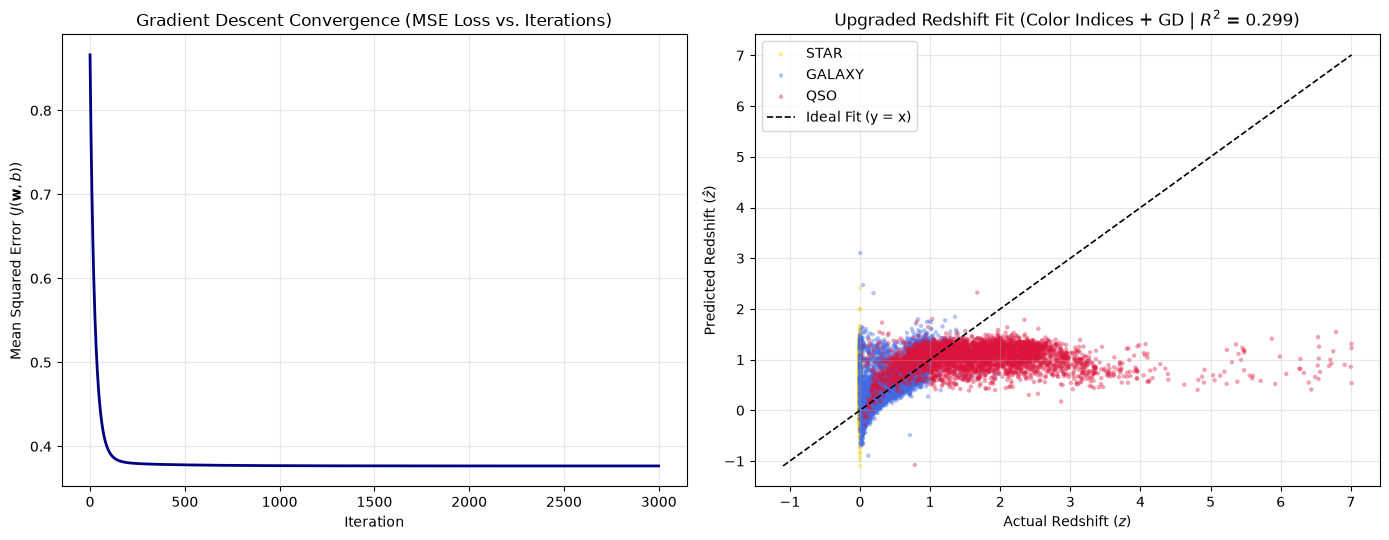

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Plot: Gradient Descent MSE Loss Curve
axes[0].plot(loss_history, color='navy', linewidth=2)
axes[0].set_title('Gradient Descent Convergence (MSE Loss vs. Iterations)')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Mean Squared Error ($J(\\mathbf{w}, b)$)')
axes[0].grid(True, alpha=0.3)

# Right Plot: Upgraded Predicted vs. Actual Redshift
for obj_class, color in CLASS_COLORS.items():
    mask = (class_eng_test.values == obj_class)
    axes[1].scatter(
        y_eng_test.values[mask], z_pred_gd[mask],
        c=color, label=obj_class, alpha=0.4, s=10, edgecolors='none'
    )

lims = [min(y_eng_test.min(), z_pred_gd.min()), max(y_eng_test.max(), z_pred_gd.max())]
axes[1].plot(lims, lims, 'k--', linewidth=1.2, label='Ideal Fit (y = x)')
axes[1].set_title(f'Upgraded Redshift Fit (Color Indices + GD | $R^2$ = {r2_gd:.3f})')
axes[1].set_xlabel('Actual Redshift ($z$)')
axes[1].set_ylabel('Predicted Redshift ($\\hat{z}$)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/04_gradient_descent_and_upgraded_fit.png', dpi=300)
plt.show()

## 6. Key Findings & Analytical Notes
* **Redshift Regression Performance:** The Linear Regression baseline achieved an $R^2$ of `[0.2789]` and an RMSE of `[0.6210]` on the unseen 20% test set.
* **Relativistic Velocity Performance:** After transforming predictions via $\beta(z)$, the velocity $R^2$ is `[0.2016]` with an RMSE of `[0.2384] c`.
* **Physical & Modeling Insight:** Nearby **Stars** cluster near $z \approx 0$ ($\beta \approx 0$), **Galaxies** occupy low-to-moderate recession speeds, and **Quasars (QSOs)** reach relativistic speeds approaching $c$. Any scatter away from the $y = x$ line at high $z$ demonstrates the physical limit of a linear model on non-linear astrophysical spectra.